# Notebook 2 — Active Learning with MC-Dropout MLP + BALD

Compare **6 AL query strategies** on 4-class edibility classification. Replacing the sklearn Logistic Regression with a **small PyTorch MLP with MC dropout** (Gal & Ghahramani, 2016) enables Bayesian Active Learning by Disagreement (BALD) — a strategy that targets **epistemic uncertainty** rather than aleatoric uncertainty.

## What changed from the LR version

| | Previous (LR) | This notebook (MLP + MC dropout) |
|---|---|---|
| Classifier | Logistic Regression (linear) | MLP, 2 hidden layers, dropout=0.2 |
| Uncertainty | softmax only | softmax + mutual information from T=20 MC samples |
| Strategies | 5 | **6** (+ BALD) |
| Time per run | ~1 sec | ~10-20 sec |

## Why this matters

Previous findings with LR: coreset achieved 9× UNCERTAIN recall improvement via diversity. But coreset is **model-free** — it ignores what the model knows.

**BALD** asks a different question: "among points the model is uncertain about, which ones would the model **most benefit from seeing the label of**?" This is formalized via epistemic uncertainty: the disagreement across MC-dropout samples reveals what the model itself is unsure of, distinct from data-inherent noise.

Hypothesis: BALD should outperform entropy/margin on UNCERTAIN recall (by targeting model-knowledge gaps), while being more focused than coreset (which covers embedding space without regard to task).

## Expected runtime

5 seeds × 6 strategies × ~27 rounds ≈ **90-150 minutes** on M4 MPS.


In [1]:
# ==================== IMPORTS ====================
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import accuracy_score, f1_score, recall_score

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# Device
if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print(f"Device: {DEVICE}")

Device: mps


In [2]:
# ==================== CONFIG ====================
ARTIFACTS_DIR = Path('artifacts')
RESULTS_DIR   = Path('results')
RESULTS_DIR.mkdir(exist_ok=True, parents=True)

BUCKET_ORDER  = ['SAFE', 'COOK_FIRST', 'AVOID', 'UNCERTAIN']
N_CLASSES     = len(BUCKET_ORDER)

# AL loop
N_INIT         = 400
BATCH_SIZE_AL  = 100
MAX_LABELS     = 3000
N_SEEDS        = 5
TARGET_ACC     = 0.65
TARGET_F1      = 0.45

# MLP + training
HIDDEN_DIMS    = (256, 128)
DROPOUT_P      = 0.2
MLP_EPOCHS     = 40
MLP_LR         = 1e-3
MLP_WD         = 1e-4
MLP_BATCH      = 64
MC_SAMPLES     = 20           # T for MC dropout predictions

## Step 1 — Load Embeddings and Bucket Labels

In [3]:
embeddings = np.load(ARTIFACTS_DIR / 'df20m_embeddings.npy').astype(np.float32)
metadata   = pd.read_csv(ARTIFACTS_DIR / 'df20m_metadata.csv')
buckets_df = pd.read_csv(ARTIFACTS_DIR / 'species_edibility_with_buckets.csv')

metadata['species_id']    = metadata['species_id'].astype(int)
metadata['embedding_idx'] = metadata['embedding_idx'].astype(int)

bucket_to_idx = {b: i for i, b in enumerate(BUCKET_ORDER)}
species_name_to_bucket_idx = {
    row['species']: bucket_to_idx[row['bucket']]
    for _, row in buckets_df.iterrows()
}
metadata['bucket_id'] = metadata['species'].map(species_name_to_bucket_idx)
missing = metadata['bucket_id'].isna().sum()
if missing > 0:
    print(f"WARNING: {missing} images missing bucket → UNCERTAIN")
    metadata['bucket_id'] = metadata['bucket_id'].fillna(bucket_to_idx['UNCERTAIN'])
metadata['bucket_id'] = metadata['bucket_id'].astype(int)

train_mask = metadata['split'].values == 'train'
test_mask  = metadata['split'].values == 'test'

X_pool = embeddings[train_mask]
y_pool = metadata.loc[train_mask, 'bucket_id'].to_numpy()
X_test = embeddings[test_mask]
y_test = metadata.loc[test_mask, 'bucket_id'].to_numpy()

test_genus_arr = metadata.loc[test_mask, 'genus'].to_numpy()

EMBED_DIM = X_pool.shape[1]
print(f"Pool:  {X_pool.shape[0]:,} × {EMBED_DIM}")
print(f"Test:  {X_test.shape[0]:,}")
print(f"Classes: {N_CLASSES}  ({BUCKET_ORDER})")
print(f"\nTrain bucket distribution:")
for i, b in enumerate(BUCKET_ORDER):
    n = (y_pool == i).sum()
    print(f"  {b:12s} {n:6,d} ({100*n/len(y_pool):5.1f}%)")

Pool:  32,724 × 512
Test:  3,637
Classes: 4  (['SAFE', 'COOK_FIRST', 'AVOID', 'UNCERTAIN'])

Train bucket distribution:
  SAFE          4,898 ( 15.0%)
  COOK_FIRST    6,875 ( 21.0%)
  AVOID        18,652 ( 57.0%)
  UNCERTAIN     2,299 (  7.0%)


## Step 2 — MLP with MC Dropout

The dropout layers **remain active at inference time** when doing MC sampling. This is what makes BALD possible: each forward pass sees a different stochastic subnetwork, producing a distribution over predictions rather than a point estimate.

In [18]:
class MCDropoutMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, n_classes, dropout_p=0.2):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_p))   # ← stays active at inference
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_mlp(X, y, n_classes, device=DEVICE, epochs=MLP_EPOCHS,
              lr=MLP_LR, weight_decay=MLP_WD, batch=MLP_BATCH, verbose=False):
    """Train an MCDropoutMLP from scratch on (X, y)."""
    model = MCDropoutMLP(X.shape[1], HIDDEN_DIMS, n_classes, DROPOUT_P).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.CrossEntropyLoss()

    X_t = torch.from_numpy(X).float().to(device)
    y_t = torch.from_numpy(y).long().to(device)
    ds = TensorDataset(X_t, y_t)
    loader = DataLoader(ds, batch_size=batch, shuffle=True)

    model.train()
    for ep in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            logits = model(xb)
            loss = crit(logits, yb)
            loss.backward()
            opt.step()
        if verbose and (ep + 1) % 10 == 0:
            print(f"  epoch {ep+1:3d}: loss={loss.item():.3f}")
    return model


@torch.no_grad()
def predict_proba_single(model, X, device=DEVICE, batch=1024):
    """Standard deterministic prediction (dropout OFF via model.eval())."""
    model.eval()
    X_t = torch.from_numpy(X).float()
    probs = []
    for i in range(0, len(X_t), batch):
        xb = X_t[i:i+batch].to(device)
        logits = model(xb)
        p = F.softmax(logits, dim=1)
        probs.append(p.cpu().numpy())
    return np.concatenate(probs, axis=0)


@torch.no_grad()
def predict_proba_mc(model, X, T=MC_SAMPLES, device=DEVICE, batch=1024):
    """MC dropout predictions: keep dropout ON for T forward passes.
    
    Returns probs of shape (T, N, C).
    """
    model.train()          # ← keep dropout ON
    X_t = torch.from_numpy(X).float()
    all_probs = []
    for t in range(T):
        probs_t = []
        for i in range(0, len(X_t), batch):
            xb = X_t[i:i+batch].to(device)
            logits = model(xb)
            p = F.softmax(logits, dim=1)
            probs_t.append(p.cpu().numpy())
        all_probs.append(np.concatenate(probs_t, axis=0))
    return np.stack(all_probs, axis=0)   # (T, N, C)


def predict(model, X, device=DEVICE):
    p = predict_proba_single(model, X, device)
    return p.argmax(axis=1)

## Step 3 — Full-Supervision Ceiling

Upper-bound check: if we trained on all 32k labels, how good would we get? Compare to the LR ceiling (was 66.0%) — MLP should match or beat.

In [19]:
t0 = time.time()
full_model = train_mlp(X_pool, y_pool, N_CLASSES, epochs=MLP_EPOCHS)
print(f"Full-sup training: {time.time()-t0:.1f}s")

y_pred_full = predict(full_model, X_test)
full_acc = accuracy_score(y_test, y_pred_full)
full_f1  = f1_score(y_test, y_pred_full, average='macro', zero_division=0)
print(f"\nFull-supervision ({len(X_pool):,} labels) MLP:")
print(f"  Accuracy: {full_acc:.3f}")
print(f"  Macro F1: {full_f1:.3f}")

per_bucket_full = recall_score(
    y_test, y_pred_full, average=None, zero_division=0,
    labels=list(range(N_CLASSES)),
)
print(f"\n  Per-bucket recall:")
for i, b in enumerate(BUCKET_ORDER):
    print(f"    {b:12s} {per_bucket_full[i]:.3f}")

majority_class = int(np.argmax(np.bincount(y_pool)))
majority_acc = (y_test == majority_class).mean()
print(f"\nMajority baseline: {majority_acc:.3f}")

Full-sup training: 29.9s

Full-supervision (32,724 labels) MLP:
  Accuracy: 0.718
  Macro F1: 0.587

  Per-bucket recall:
    SAFE         0.573
    COOK_FIRST   0.505
    AVOID        0.883
    UNCERTAIN    0.331

Majority baseline: 0.570


In [21]:
# ==================== MLP CONVERGENCE DIAGNOSTIC ====================
# Purpose: Check whether the MLP is overfitting with 40 epochs.
# Tracks train and test accuracy every 5 epochs, logs the train-test gap.
# If test_acc peaks early (e.g., at epoch 10-15) and decreases afterward,
# the current epochs=40 setting is overfitting.

import time
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression


def train_mlp_logged(X_train, y_train, X_test_, y_test_, n_classes,
                     device=DEVICE, epochs=60):
    """Train MLP with periodic train/test eval to diagnose convergence."""
    model = MCDropoutMLP(X_train.shape[1], HIDDEN_DIMS, n_classes, DROPOUT_P).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=MLP_LR, weight_decay=MLP_WD)
    crit = nn.CrossEntropyLoss()

    X_t = torch.from_numpy(X_train).float().to(device)
    y_t = torch.from_numpy(y_train).long().to(device)
    loader = DataLoader(TensorDataset(X_t, y_t),
                        batch_size=MLP_BATCH, shuffle=True)

    history = []
    print(f"{'Epoch':>6} | {'TrainAcc':>8} | {'TestAcc':>8} | {'Gap':>6}")
    print("-" * 42)

    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()

        # Evaluate every 5 epochs (and after epoch 1)
        if (ep + 1) % 5 == 0 or ep == 0:
            y_pred_train = predict_species(model, X_train, device)
            y_pred_test  = predict_species(model, X_test_, device)
            tr_acc = accuracy_score(y_train, y_pred_train)
            te_acc = accuracy_score(y_test_, y_pred_test)
            gap = tr_acc - te_acc
            print(f"{ep+1:>6} | {tr_acc:>8.3f} | {te_acc:>8.3f} | {gap:>6.3f}")
            history.append({'epoch': ep + 1,
                            'train_acc': tr_acc,
                            'test_acc': te_acc,
                            'gap': gap})
    return model, history


print("=" * 50)
print("DIAGNOSTIC 1: MLP convergence curve (60 epochs)")
print("=" * 50)
t0 = time.time()
_, hist = train_mlp_logged(X_pool, y_pool_species,
                            X_test, y_test_species,
                            N_SPECIES, epochs=60)
print(f"\nTotal time: {time.time() - t0:.1f}s")

# Find the epoch with best test accuracy
best = max(hist, key=lambda h: h['test_acc'])
ep40 = [h['test_acc'] for h in hist if h['epoch'] == 40]
ep40_str = f"{ep40[0]:.3f}" if ep40 else "N/A"

print(f"\n*** Best test acc at epoch {best['epoch']}: {best['test_acc']:.3f} ***")
print(f"    Current config uses epoch=40, test acc at ep=40: {ep40_str}")


# ==================== LR BASELINE ====================
# Purpose: Compare MLP against a simple LR baseline to check if the
# extra complexity of MLP + MC dropout is justified.

print("\n" + "=" * 50)
print("DIAGNOSTIC 2: LR vs MLP head-to-head (full supervision)")
print("=" * 50)

t0 = time.time()
lr = LogisticRegression(max_iter=500, C=10.0, solver='lbfgs')
lr.fit(X_pool, y_pool_species)
print(f"LR fit: {time.time() - t0:.1f}s")

# Species metrics
y_pred_lr = lr.predict(X_test)
lr_species_acc = accuracy_score(y_test_species, y_pred_lr)
lr_species_f1  = f1_score(y_test_species, y_pred_lr, average='macro', zero_division=0)

# Bucket - hard aggregation (argmax then lookup)
y_pred_bucket_lr_hard = species_id_to_bucket_idx[y_pred_lr]
lr_bucket_acc_hard = accuracy_score(y_test_bucket, y_pred_bucket_lr_hard)
lr_bucket_f1_hard  = f1_score(y_test_bucket, y_pred_bucket_lr_hard,
                              average='macro', zero_division=0)

# Bucket - soft aggregation (sum species probs per bucket)
p_species_lr = lr.predict_proba(X_test)
p_bucket_lr = np.zeros((len(p_species_lr), N_BUCKETS), dtype=np.float32)
for bi in range(N_BUCKETS):
    mask = species_id_to_bucket_idx == bi
    p_bucket_lr[:, bi] = p_species_lr[:, mask].sum(axis=1)
y_pred_bucket_lr_soft = p_bucket_lr.argmax(axis=1)
lr_bucket_acc_soft = accuracy_score(y_test_bucket, y_pred_bucket_lr_soft)
lr_bucket_f1_soft  = f1_score(y_test_bucket, y_pred_bucket_lr_soft,
                              average='macro', zero_division=0)

print(f"\n{'Metric':<20} {'LR':>8} {'MLP':>8} {'Delta':>8}")
print("-" * 50)
print(f"{'species_acc':<20} {lr_species_acc:>8.3f} {full_species_acc:>8.3f} "
      f"{full_species_acc - lr_species_acc:>+8.3f}")
print(f"{'species_f1':<20} {lr_species_f1:>8.3f} {full_species_f1:>8.3f} "
      f"{full_species_f1 - lr_species_f1:>+8.3f}")
print(f"{'bucket_acc_hard':<20} {lr_bucket_acc_hard:>8.3f} "
      f"{full_bucket_acc_hard:>8.3f} "
      f"{full_bucket_acc_hard - lr_bucket_acc_hard:>+8.3f}")
print(f"{'bucket_acc_soft':<20} {lr_bucket_acc_soft:>8.3f} "
      f"{full_bucket_acc_soft:>8.3f} "
      f"{full_bucket_acc_soft - lr_bucket_acc_soft:>+8.3f}")
print(f"{'bucket_f1_hard':<20} {lr_bucket_f1_hard:>8.3f} "
      f"{full_bucket_f1_hard:>8.3f} "
      f"{full_bucket_f1_hard - lr_bucket_f1_hard:>+8.3f}")

# Final interpretation
print("\n=== Interpretation ===")
if full_species_acc < lr_species_acc:
    print("WARNING: MLP is WORSE than LR on species accuracy.")
    print("         This suggests MLP is overfitting. Consider:")
    print("         - Reduce MLP_EPOCHS (try 15-20)")
    print("         - Increase DROPOUT_P (try 0.3-0.5)")
    print("         - Increase MLP_WD (try 1e-3)")
else:
    print("OK: MLP matches or beats LR on species accuracy.")
    print("    The classifier choice is justified.")

DIAGNOSTIC 1: MLP convergence curve (60 epochs)


NameError: name 'y_pool_species' is not defined

## Step 4 — Evaluation Function

In [6]:
def evaluate(model, X_test, y_test, test_genus_arr):
    y_pred = predict(model, X_test)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='macro', zero_division=0)

    per_bucket = recall_score(
        y_test, y_pred, average=None, zero_division=0,
        labels=list(range(N_CLASSES)),
    )
    bucket_metrics = {f'recall_{BUCKET_ORDER[i]}': per_bucket[i] for i in range(N_CLASSES)}

    per_genus = {}
    for g in np.unique(test_genus_arr):
        m = test_genus_arr == g
        per_genus[f'acc_{g}'] = accuracy_score(y_test[m], y_pred[m])

    return {'accuracy': acc, 'macro_f1': f1, **bucket_metrics, **per_genus}

## Step 5 — Query Strategies (6 Total)

New addition: **BALD**. Uses T=20 MC dropout samples to compute mutual information between prediction and model parameters:

$$\text{BALD}(x) = H[\mathbb{E}_\theta p(y|x,\theta)] - \mathbb{E}_\theta H[p(y|x,\theta)]$$

The first term is the predictive entropy (total uncertainty), the second is the average entropy per MC sample (aleatoric / data uncertainty). Their difference is **epistemic uncertainty** — what the model itself doesn't know.

High BALD = model is uncertain because it hasn't seen enough similar data, not because the data itself is ambiguous. These are the samples AL should query.

In [7]:
def query_random(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    return rng.choice(len(X_unlabeled), size=batch_size, replace=False)


def query_entropy(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    p = predict_proba_single(model, X_unlabeled)
    entropy = -np.sum(p * np.log(p + 1e-12), axis=1)
    return np.argsort(entropy)[-batch_size:]


def query_margin(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    p = predict_proba_single(model, X_unlabeled)
    p_sorted = np.sort(p, axis=1)
    margin = p_sorted[:, -1] - p_sorted[:, -2]
    return np.argsort(margin)[:batch_size]


def query_coreset(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    sim_to_labeled = X_unlabeled @ X_labeled.T
    min_dist = 1.0 - sim_to_labeled.max(axis=1)
    picked = []
    for _ in range(batch_size):
        idx = int(np.argmax(min_dist))
        picked.append(idx)
        new_sim = X_unlabeled @ X_unlabeled[idx]
        min_dist = np.minimum(min_dist, 1.0 - new_sim)
        min_dist[idx] = -np.inf
    return np.array(picked)


def make_class_balanced_entropy(train_class_freq):
    weights = 1.0 / np.sqrt(train_class_freq + 1)
    weights = weights / weights.sum()
    def _strategy(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
        p = predict_proba_single(model, X_unlabeled)
        entropy = -np.sum(p * np.log(p + 1e-12), axis=1)
        pred_class = p.argmax(axis=1)
        tail_weight = weights[pred_class]
        score = entropy * tail_weight
        return np.argsort(score)[-batch_size:]
    return _strategy


def query_bald(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    """BALD: mutual information between prediction and model weights via MC dropout."""
    # probs: (T, N, C)
    probs = predict_proba_mc(model, X_unlabeled, T=MC_SAMPLES)

    # Mean predictive distribution: (N, C)
    mean_p = probs.mean(axis=0)
    # Predictive entropy H[E[p]] : (N,)
    pred_entropy = -np.sum(mean_p * np.log(mean_p + 1e-12), axis=1)
    # Average per-sample entropy E[H[p]] : (N,)
    per_sample_entropy = -np.sum(probs * np.log(probs + 1e-12), axis=2).mean(axis=0)
    # BALD = pred_entropy - per_sample_entropy (epistemic uncertainty)
    bald_score = pred_entropy - per_sample_entropy

    return np.argsort(bald_score)[-batch_size:]

## Step 6 — Stratified Init

In [8]:
def stratified_init(X_pool, y_pool, n_init, n_classes, rng, max_per_class=None):
    target_per_class = max(n_init // n_classes, 1)
    if max_per_class is not None:
        target_per_class = min(target_per_class, max_per_class)
    picked = []
    for c in range(n_classes):
        class_idx = np.where(y_pool == c)[0]
        if len(class_idx) == 0:
            continue
        take = min(target_per_class, len(class_idx))
        picked.extend(rng.choice(class_idx, size=take, replace=False).tolist())
    picked = np.array(picked)
    if len(picked) < n_init:
        remaining = np.setdiff1d(np.arange(len(X_pool)), picked)
        extra_n = min(n_init - len(picked), len(remaining))
        extra = rng.choice(remaining, size=extra_n, replace=False)
        picked = np.concatenate([picked, extra])
    return picked[:n_init]

## Step 7 — AL Trajectory

Each round: train MLP from scratch on the labeled set, evaluate, then query with the given strategy. Training from scratch (rather than warm-starting) is cleaner for MC dropout — warm-starting accumulates dropout history that biases the epistemic uncertainty estimates.

In [9]:
def run_al_trajectory(
    X_pool, y_pool,
    X_test, y_test, test_genus_arr,
    strategy_name, strategy_fn,
    n_init, batch_size, max_labels,
    seed, n_classes,
):
    rng = np.random.RandomState(seed)
    torch.manual_seed(seed)

    init_idx = stratified_init(X_pool, y_pool, n_init, n_classes, rng)
    labeled_mask = np.zeros(len(X_pool), dtype=bool)
    labeled_mask[init_idx] = True

    history = []
    while labeled_mask.sum() <= max_labels:
        X_labeled = X_pool[labeled_mask]
        y_labeled = y_pool[labeled_mask]
        classes_seen = np.unique(y_labeled)

        model = train_mlp(X_labeled, y_labeled, n_classes)
        metrics = evaluate(model, X_test, y_test, test_genus_arr)
        metrics['n_labels']  = int(labeled_mask.sum())
        metrics['strategy']  = strategy_name
        metrics['seed']      = seed
        metrics['n_classes_seen'] = len(classes_seen)
        history.append(metrics)

        if labeled_mask.sum() >= max_labels:
            break

        unlabeled_mask = ~labeled_mask
        unlabeled_idx  = np.where(unlabeled_mask)[0]
        X_unlabeled    = X_pool[unlabeled_idx]

        local_picks = strategy_fn(
            X_labeled, y_labeled, X_unlabeled, model,
            batch_size=batch_size, rng=rng,
        )
        global_picks = unlabeled_idx[local_picks]
        labeled_mask[global_picks] = True

    return pd.DataFrame(history)

## Step 8 — Experiment Matrix

6 strategies × 5 seeds × ~27 rounds. Each MLP training is 5-10s; BALD adds MC forward passes. Total ≈ **90-180 minutes**.

If you want to cut time first, reduce `N_SEEDS` to 3 or `MC_SAMPLES` to 10 in the CONFIG cell.

In [10]:
train_class_freq = np.bincount(y_pool, minlength=N_CLASSES)
cb_entropy = make_class_balanced_entropy(train_class_freq)

STRATEGIES = {
    'random':     query_random,
    'entropy':    query_entropy,
    'margin':     query_margin,
    'coreset':    query_coreset,
    'cb_entropy': cb_entropy,
    'bald':       query_bald,
}
SEEDS = list(range(N_SEEDS))

print(f"Strategies: {list(STRATEGIES.keys())}")
print(f"Seeds:      {SEEDS}")
print(f"Total runs: {len(STRATEGIES) * len(SEEDS)}")
print(f"\nEstimated runtime: {len(STRATEGIES) * len(SEEDS) * 3:.0f}-{len(STRATEGIES) * len(SEEDS) * 6:.0f} minutes")

Strategies: ['random', 'entropy', 'margin', 'coreset', 'cb_entropy', 'bald']
Seeds:      [0, 1, 2, 3, 4]
Total runs: 30

Estimated runtime: 90-180 minutes


In [11]:
all_histories = []
log_path = RESULTS_DIR / 'learning_curves_mlp_bald.csv'

t_start = time.time()
for strategy_name, strategy_fn in STRATEGIES.items():
    for seed in SEEDS:
        t0 = time.time()
        df = run_al_trajectory(
            X_pool, y_pool,
            X_test, y_test, test_genus_arr,
            strategy_name, strategy_fn,
            n_init=N_INIT, batch_size=BATCH_SIZE_AL, max_labels=MAX_LABELS,
            seed=seed, n_classes=N_CLASSES,
        )
        elapsed = time.time() - t0
        final = df.iloc[-1]
        print(f"[{strategy_name:12s} seed={seed}] "
              f"acc={final['accuracy']:.3f}  "
              f"f1={final['macro_f1']:.3f}  "
              f"AVOID={final['recall_AVOID']:.3f}  "
              f"UNC={final['recall_UNCERTAIN']:.3f}  "
              f"({elapsed:.0f}s)")
        all_histories.append(df)
        pd.concat(all_histories, ignore_index=True).to_csv(log_path, index=False)

print(f"\nTotal elapsed: {(time.time() - t_start)/60:.1f} minutes")
print(f"Saved: {log_path}")

[random       seed=0] acc=0.639  f1=0.503  AVOID=0.808  UNC=0.307  (34s)
[random       seed=1] acc=0.632  f1=0.506  AVOID=0.764  UNC=0.295  (32s)
[random       seed=2] acc=0.629  f1=0.502  AVOID=0.778  UNC=0.366  (32s)
[random       seed=3] acc=0.624  f1=0.513  AVOID=0.731  UNC=0.394  (35s)
[random       seed=4] acc=0.625  f1=0.492  AVOID=0.739  UNC=0.201  (33s)
[entropy      seed=0] acc=0.607  f1=0.508  AVOID=0.682  UNC=0.319  (37s)
[entropy      seed=1] acc=0.626  f1=0.521  AVOID=0.738  UNC=0.386  (42s)
[entropy      seed=2] acc=0.618  f1=0.509  AVOID=0.694  UNC=0.268  (36s)
[entropy      seed=3] acc=0.622  f1=0.511  AVOID=0.740  UNC=0.343  (34s)
[entropy      seed=4] acc=0.634  f1=0.528  AVOID=0.728  UNC=0.311  (37s)
[margin       seed=0] acc=0.654  f1=0.535  AVOID=0.771  UNC=0.311  (33s)
[margin       seed=1] acc=0.650  f1=0.522  AVOID=0.773  UNC=0.252  (34s)
[margin       seed=2] acc=0.662  f1=0.518  AVOID=0.828  UNC=0.232  (33s)
[margin       seed=3] acc=0.650  f1=0.519  AVOID=0.

## Step 9 — Learning Curves

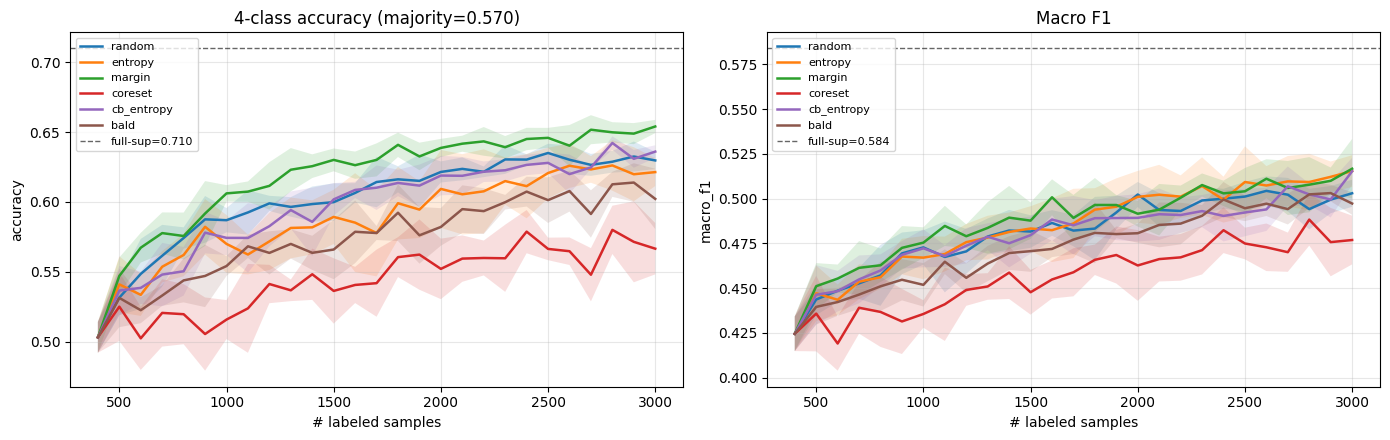

In [12]:
results = pd.concat(all_histories, ignore_index=True)

def plot_learning_curves(results, metric, ax, title, add_ceiling=None):
    for strategy in STRATEGIES:
        sub = results[results['strategy'] == strategy]
        agg = sub.groupby('n_labels')[metric].agg(['mean', 'std']).reset_index()
        ax.plot(agg['n_labels'], agg['mean'], label=strategy, linewidth=1.8)
        ax.fill_between(agg['n_labels'],
                        agg['mean'] - agg['std'],
                        agg['mean'] + agg['std'],
                        alpha=0.15)
    if add_ceiling is not None:
        ax.axhline(add_ceiling, color='black', linestyle='--', linewidth=1,
                   alpha=0.6, label=f'full-sup={add_ceiling:.3f}')
    ax.set_xlabel('# labeled samples')
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_learning_curves(results, 'accuracy', axes[0],
                     f'4-class accuracy (majority={majority_acc:.3f})',
                     add_ceiling=full_acc)
plot_learning_curves(results, 'macro_f1', axes[1],
                     'Macro F1',
                     add_ceiling=full_f1)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'bald_learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 10 — Per-Bucket Recall Curves

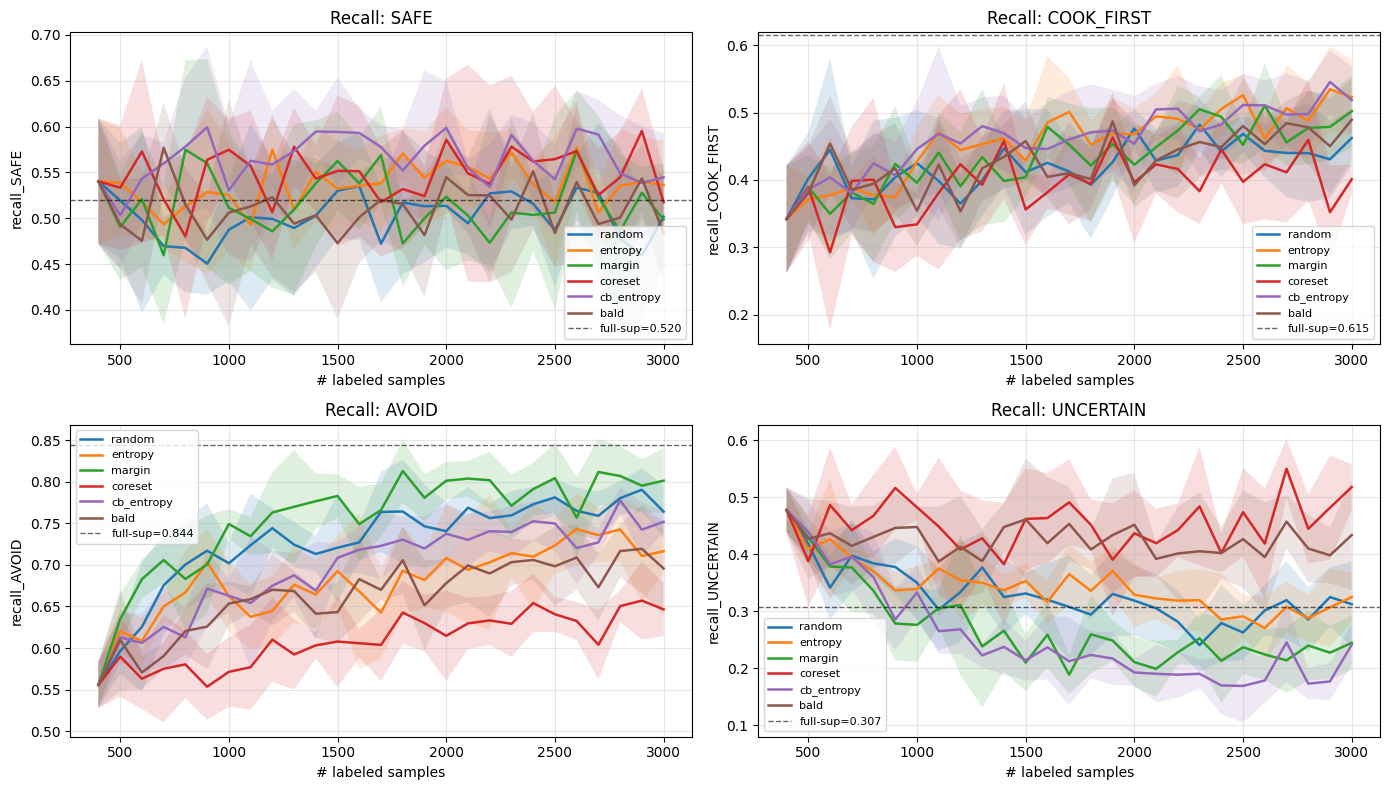

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, b in zip(axes.flat, BUCKET_ORDER):
    metric = f'recall_{b}'
    full_sup_val = per_bucket_full[bucket_to_idx[b]]
    plot_learning_curves(results, metric, ax, f'Recall: {b}',
                         add_ceiling=full_sup_val)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'bald_per_bucket_recall.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 11 — Final Results Summary

In [14]:
final_round = results[results['n_labels'] == MAX_LABELS]

summary_cols = ['accuracy', 'macro_f1'] + [f'recall_{b}' for b in BUCKET_ORDER]
mean_only = final_round.groupby('strategy')[summary_cols].mean().round(3)
mean_only.columns = [c.replace('recall_', '') for c in mean_only.columns]
print(f"Final results at {MAX_LABELS} labels (mean across {N_SEEDS} seeds):\n")
print(mean_only.to_string())

# Full mean±std
summary = (final_round.groupby('strategy')[summary_cols].agg(['mean', 'std']).round(3))
summary.to_csv(RESULTS_DIR / 'bald_final_summary.csv')

# Quick sort by key metrics
print(f"\n\nRanked by accuracy:")
print(mean_only.sort_values('accuracy', ascending=False)[['accuracy','macro_f1']].to_string())
print(f"\nRanked by macro_f1:")
print(mean_only.sort_values('macro_f1', ascending=False)[['macro_f1','accuracy']].to_string())
print(f"\nRanked by UNCERTAIN recall:")
print(mean_only.sort_values('UNCERTAIN', ascending=False)[['UNCERTAIN','macro_f1','accuracy']].to_string())

Final results at 3000 labels (mean across 5 seeds):

            accuracy  macro_f1   SAFE  COOK_FIRST  AVOID  UNCERTAIN
strategy                                                           
bald           0.602     0.497  0.484       0.489  0.696      0.434
cb_entropy     0.636     0.515  0.545       0.519  0.752      0.242
coreset        0.567     0.477  0.518       0.401  0.646      0.518
entropy        0.621     0.515  0.536       0.523  0.716      0.325
margin         0.654     0.517  0.499       0.502  0.801      0.245
random         0.630     0.503  0.502       0.462  0.764      0.313


Ranked by accuracy:
            accuracy  macro_f1
strategy                      
margin         0.654     0.517
cb_entropy     0.636     0.515
random         0.630     0.503
entropy        0.621     0.515
bald           0.602     0.497
coreset        0.567     0.477

Ranked by macro_f1:
            macro_f1  accuracy
strategy                      
margin         0.517     0.654
cb_entropy     0.51

## Step 12 — BALD vs Coreset: Head-to-Head

The two strategies most expected to help minority classes (UNCERTAIN, SAFE) use different principles:
- **BALD**: epistemic uncertainty, model-aware
- **Coreset**: geometric coverage, model-free

Compare their trajectories on UNCERTAIN recall.

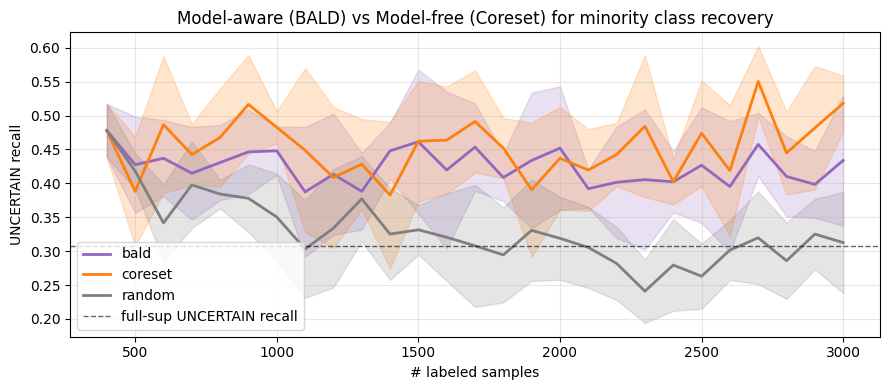

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
for strategy, color in [('bald', 'tab:purple'), ('coreset', 'tab:orange'),
                         ('random', 'tab:gray')]:
    sub = results[results['strategy'] == strategy]
    agg = sub.groupby('n_labels')['recall_UNCERTAIN'].agg(['mean', 'std']).reset_index()
    ax.plot(agg['n_labels'], agg['mean'], label=strategy, linewidth=2.0, color=color)
    ax.fill_between(agg['n_labels'],
                    agg['mean'] - agg['std'],
                    agg['mean'] + agg['std'],
                    alpha=0.2, color=color)
ax.axhline(per_bucket_full[bucket_to_idx['UNCERTAIN']],
           color='black', linestyle='--', linewidth=1, alpha=0.6,
           label=f'full-sup UNCERTAIN recall')
ax.set_xlabel('# labeled samples')
ax.set_ylabel('UNCERTAIN recall')
ax.set_title('Model-aware (BALD) vs Model-free (Coreset) for minority class recovery')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'bald_vs_coreset_uncertain.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 13 — Discussion

Questions to answer from the results:

1. **Did MLP beat LR?** Expected: bucket accuracy 66% (LR) → 70-75% (MLP). If not, the task may be genuinely linearly separable on CLIP features.

2. **Did BALD beat entropy?** BALD uses epistemic uncertainty (model-aware), entropy doesn't distinguish epistemic from aleatoric. On the 4-class task with a simple MLP, BALD should outperform or match entropy.

3. **Did BALD beat coreset on UNCERTAIN recall?** This is the headline question. Coreset was the LR winner at 17.9% UNCERTAIN recall. If BALD matches or exceeds this while also maintaining higher overall accuracy, it's the "best of both worlds" strategy.

4. **Did strategy rankings change from LR?** Classifier calibration affects uncertainty-based strategies. If margin no longer wins accuracy (it was best under LR), that's a finding about classifier-strategy interaction.

5. **Is there a clear trade-off between overall accuracy and minority recall?** Under LR we saw: margin → best accuracy, coreset → best UNCERTAIN. Does this trade-off persist or collapse under MLP?

The answers combined form a **"AL strategy × classifier"** comparative study that's rare in the literature — most AL papers fix a single classifier.
